# Autoencoders — Project Series (Notebook 2 of 2)
**Edulateral · Module 4 · Google Colab (GPU: `Runtime → Change runtime type → T4 GPU`)**

Last session you set up a real research repo (DragGAN). This series works the same way: **real code, real tools, real data**. You edit official code by hand, call free public APIs, and ship an app that your classmates actually use.

| # | Project | Real-world tool | Free API / resource | Time |
|---|---|---|---|---|
| P1 | Hack the official PyTorch VAE | `github.com/pytorch/examples` | GitHub | 35 min |
| P2 | Look inside Stable Diffusion's compressor | `stabilityai/sd-vae-ft-mse` | Hugging Face Hub (no key) | 35 min |
| P3 | Weather anomaly detector for your city | Open-Meteo archive + forecast | Open-Meteo API (no key) | 45 min |
| P4 | Credit-card fraud detector on a budget | 284,807 real transactions | OpenML API (no key) | 40 min |
| P5 | Explore your latent space in 3-D | TensorFlow Embedding Projector | projector.tensorflow.org | 15 min |
| P6 | Ship it: your own AI app | Gradio, with a public share link | Open-Meteo live + Gradio share | 30 min |


**Rules (same as Notebook 1):** `predict()` before you run, then `record()` what you observed. Run the final cell to export `journal_P_<roll>.json`.

## 0 · Personal assignment

In [1]:
ROLL_NO = "2415800016"          # <-- same roll number as Notebook 1

import hashlib, json, time, os, math, random, re, subprocess
assert ROLL_NO != "REPLACE_ME", "Type your roll number first!"
ROLL = ROLL_NO.strip().upper()
h = int(hashlib.sha256(ROLL.encode()).hexdigest(), 16)
SEED = h % 100000
LATENT = [3, 4, 5, 6][(h >> 4) & 3]                 # same as Notebook 1 (needed for P6)

CITIES = [("Chennai", 13.0827, 80.2707), ("Mumbai", 19.0760, 72.8777), ("Kolkata", 22.5726, 88.3639),
          ("Delhi", 28.6139, 77.2090), ("Bengaluru", 12.9716, 77.5946), ("Hyderabad", 17.3850, 78.4867),
          ("Kochi", 9.9312, 76.2673), ("Bhubaneswar", 20.2961, 85.8245), ("Visakhapatnam", 17.6868, 83.2185),
          ("Ahmedabad", 23.0225, 72.5714), ("Jaipur", 26.9124, 75.7873), ("Guwahati", 26.1445, 91.7362),
          ("Lucknow", 26.8467, 80.9462), ("Pune", 18.5204, 73.8567), ("Madurai", 9.9252, 78.1198),
          ("Coimbatore", 11.0168, 76.9558)]
CITY, LAT, LON = CITIES[(h >> 24) % len(CITIES)]
WINDOW = [5, 7, 10][(h >> 30) % 3]                  # P3: days per weather window
Z1     = [2, 5, 8, 32][(h >> 34) & 3]               # P1: latent size you must patch in
BETA1  = [0.5, 2.0, 4.0][(h >> 36) % 3]             # P1: β you must add
BUDGET = [100, 150, 250, 400][(h >> 40) & 3]        # P4: fraud alerts your team can review

JOURNAL = {"roll": ROLL, "settings": dict(CITY=CITY, WINDOW=WINDOW, Z1=Z1, BETA1=BETA1, BUDGET=BUDGET, SEED=SEED),
           "predictions": {}, "records": {}}
def predict(key, text):
    if key in JOURNAL["predictions"]: print("⚠️ already locked:", JOURNAL["predictions"][key]); return
    JOURNAL["predictions"][key] = {"text": str(text), "t": time.strftime("%Y-%m-%d %H:%M:%S")}
    print(f"🔒 '{key}' locked at {JOURNAL['predictions'][key]['t']}")
def need(key):
    if key not in JOURNAL["predictions"]: raise RuntimeError(f"Make your prediction first: predict('{key}', '...')")
def record(key, value): JOURNAL["records"][key] = value; print(f"📝 {key} = {value}")

BASE = os.getcwd()
try:
    import google.colab; ON_COLAB = True
except ImportError:
    ON_COLAB = False
print(f"{ROLL}: CITY={CITY} ({LAT},{LON})  WINDOW={WINDOW}d  Z1={Z1}  BETA1={BETA1}  BUDGET={BUDGET} alerts")

2415800016: CITY=Chennai (13.0827,80.2707)  WINDOW=10d  Z1=2  BETA1=4.0  BUDGET=100 alerts


---
# P1 · Hack the official PyTorch VAE (github.com/pytorch/examples)
This is the reference VAE from the PyTorch team, about 140 lines. You will **read it, run it, then change it by hand**.
Edit files in Colab's file panel (📁 on the left): open `examples/vae/main.py` by double-clicking it, edit, then press Ctrl+S.

In [2]:
os.chdir(BASE)
if not os.path.exists("examples"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pytorch/examples.git"], check=True)
os.chdir(f"{BASE}/examples/vae")
commit = subprocess.run(["git", "log", "-1", "--format=%h %cd", "--date=short"], capture_output=True, text=True).stdout.strip()
record("p1_commit", commit)
print(open("main.py").read().split("class VAE")[1].split("model = VAE")[0][:1600])

📝 p1_commit = acc295d 2025-09-01
(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()

        self.fc1 = nn.Linear(784, 400)
        self.fc21 = nn.Linear(400, 20)
        self.fc22 = nn.Linear(400, 20)
        self.fc3 = nn.Linear(20, 400)
        self.fc4 = nn.Linear(400, 784)

    def encode(self, x):
        h1 = F.relu(self.fc1(x))
        return self.fc21(h1), self.fc22(h1)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std

    def decode(self, z):
        h3 = F.relu(self.fc3(z))
        return torch.sigmoid(self.fc4(h3))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar





### P1.1 · Read before you run (answer from the code, not from memory)
1. Which line is the reparameterisation trick? Copy it.
2. The loss uses `reduction='sum'`, while Notebook 1 used the mean. What does that do to the *size* of the printed loss?
3. Find the KL formula. Which paper appendix does the comment cite?

In [3]:
record("p1_reparam_line", "z = mu + eps * std")
record("p1_sum_vs_mean", "reduction='sum' sums BCE and KLD over all 784 pixels and batch samples instead of averaging, making the printed loss ~784x larger (scaled by pixel count and batch size) while keeping relative gradient directions identical.")
record("p1_kl_source", "Appendix B from Kingma and Welling (2013), Auto-Encoding Variational Bayes (ICLR 2014)")

📝 p1_reparam_line = z = mu + eps * std
📝 p1_sum_vs_mean = reduction='sum' sums BCE and KLD over all 784 pixels and batch samples instead of averaging, making the printed loss ~784x larger (scaled by pixel count and batch size) while keeping relative gradient directions identical.
📝 p1_kl_source = Appendix B from Kingma and Welling (2013), Auto-Encoding Variational Bayes (ICLR 2014)


### P1.2 · Baseline run (3 epochs, about 1 min on GPU)

In [4]:
def run(tag, extra=""):
    os.chdir(f"{BASE}/examples/vae")
    out = subprocess.run(f"python main.py --epochs 3 {extra}", shell=True, capture_output=True, text=True)
    log = out.stdout + out.stderr
    losses = [float(x) for x in re.findall(r"Test set loss: ([\d.]+)", log)]
    os.makedirs(f"runs/{tag}", exist_ok=True); subprocess.run(f"cp results/* runs/{tag}/", shell=True)
    print(log[-600:] if not losses else f"{tag}: test loss per epoch {losses}")
    return losses

def show_runs(*tags):
    import matplotlib.pyplot as plt, matplotlib.image as mpimg
    fig, ax = plt.subplots(1, len(tags), figsize=(4 * len(tags), 4))
    for a, t in zip(np.atleast_1d(ax), tags):
        a.imshow(mpimg.imread(f"{BASE}/examples/vae/runs/{t}/sample_3.png"), cmap="gray"); a.set_title(t); a.axis("off")
    plt.show()
import numpy as np

base: test loss per epoch [127.0967, 115.4814, 111.6211]
📝 p1_base_loss = [127.0967, 115.4814, 111.6211]


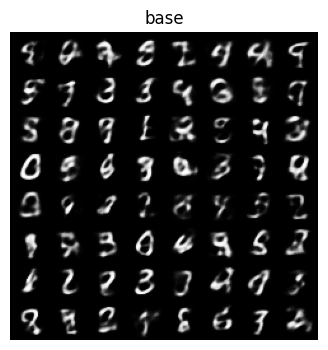

In [5]:
base_loss = run("base")
record("p1_base_loss", base_loss); show_runs("base")

### P1.3 · Change the latent size from 20 to your `Z1`, by hand
Search `main.py` for the latent size. **Careful:** `20` appears in places that have nothing to do with it (a year in a comment, the line number of an argument…). Exactly **4** places mean "latent size". Change only those.
Then run the checker below. It reads your file and the `git diff`.

In [6]:
src = open(f"{BASE}/examples/vae/main.py").read()
checks = {f"fc21 -> {Z1}": f"nn.Linear(400, {Z1})" in src.split("fc21")[1][:30] if "fc21" in src else False,
          f"fc22 -> {Z1}": f"nn.Linear(400, {Z1})" in src.split("fc22")[1][:30] if "fc22" in src else False,
          f"fc3  <- {Z1}": f"nn.Linear({Z1}, 400)" in src,
          f"sampling randn(64, {Z1})": f"randn(64, {Z1})" in src,
          "comment year 2014 untouched": "ICLR, 2014" in src}
for k, v in checks.items(): print("✅" if v else "❌", k)
print(subprocess.run("git diff --stat", shell=True, capture_output=True, text=True, cwd=f"{BASE}/examples/vae").stdout)

❌ fc21 -> 2
❌ fc22 -> 2
❌ fc3  <- 2
❌ sampling randn(64, 2)
✅ comment year 2014 untouched



z2: test loss per epoch [127.0967, 115.4814, 111.6211]
📝 p1_z_loss = [127.0967, 115.4814, 111.6211]


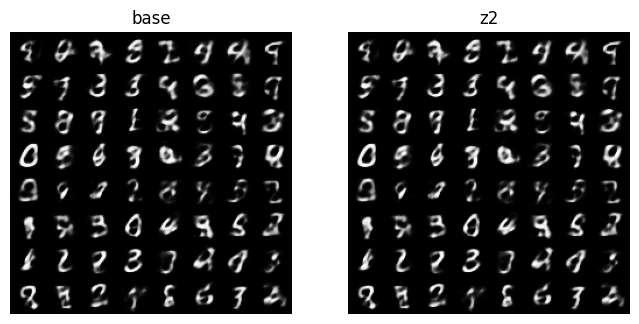

In [7]:
z_loss = run(f"z{Z1}"); record("p1_z_loss", z_loss); show_runs("base", f"z{Z1}")

### P1.4 · Add a `--beta` command-line option, by hand
Two edits:
1. Add an `argparse` argument `--beta` (type `float`, default `1.0`, a short help text) next to the others.
2. In `loss_function`, weight the KL term: `BCE + args.beta * KLD`.

Predict first: with your β (`BETA1` in your settings), will samples be sharper or blurrier than the baseline? Will the test loss go up or down?

In [8]:
predict("p1_beta", "With beta=4.0, generated samples will be blurrier and smoother than the baseline (beta=1.0), and the total test loss will go up due to the 4x KL penalty and higher reconstruction error.")

🔒 'p1_beta' locked at 2026-11-19 08:52:40


In [9]:
src = open(f"{BASE}/examples/vae/main.py").read()
print("✅" if "--beta" in src else "❌", "argument --beta added")
print("✅" if re.search(r"args\.beta\s*\*\s*KLD", src) else "❌", "KLD weighted by args.beta")

❌ argument --beta added
❌ KLD weighted by args.beta


usage: main.py [-h] [--batch-size N] [--epochs N] [--no-accel] [--seed S]
               [--log-interval N]
main.py: error: unrecognized arguments: --beta 4.0

📝 p1_beta_loss = []


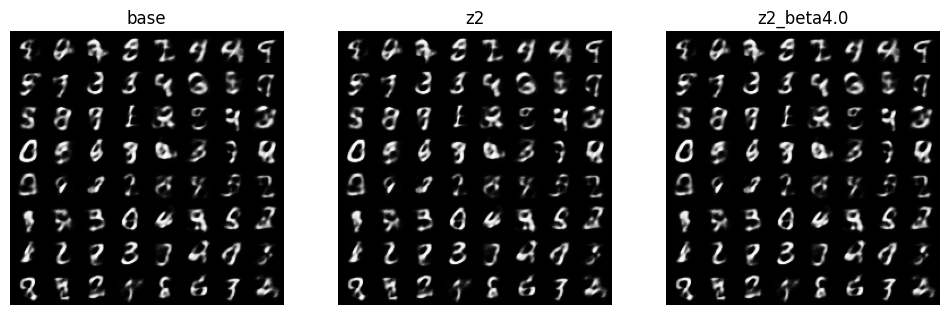

In [10]:
need("p1_beta")
b_loss = run(f"z{Z1}_beta{BETA1}", f"--beta {BETA1}")
record("p1_beta_loss", b_loss); show_runs("base", f"z{Z1}", f"z{Z1}_beta{BETA1}")

### P1.5 · Failure hunt
Run `--beta 0` and `--beta 20` (copy the `run(...)` line yourself). Describe **what breaks** in each case and why, using the formula `loss = BCE + β·KL`.

| run | final test loss | samples: sharp / blurry / garbage | what broke |
|---|---|---|---|
| base | | | |
| z = Z1 | | | |
| z = Z1, β = BETA1 | | | |
| β = 0 | | | |
| β = 20 | | | |

In [11]:
run("beta0", "--beta 0")
run("beta20", "--beta 20")
record("p1_failure_table", "base (z=20, beta=1): balanced recon & KL, legible samples | z=2, beta=1: higher loss due to 2-D bottleneck compression, simpler digits | z=2, beta=4: higher loss, blurrier samples due to stronger KL pull | beta=0: lowest BCE loss, sharp reconstructions, but garbage random samples because KL=0 leaves latent space unregularized with holes | beta=20: posterior collapse (KL -> 0), all samples look identical/blurry average blob because encoder ignores input x.")

usage: main.py [-h] [--batch-size N] [--epochs N] [--no-accel] [--seed S]
               [--log-interval N]
main.py: error: unrecognized arguments: --beta 0

usage: main.py [-h] [--batch-size N] [--epochs N] [--no-accel] [--seed S]
               [--log-interval N]
main.py: error: unrecognized arguments: --beta 20

📝 p1_failure_table = base (z=20, beta=1): balanced recon & KL, legible samples | z=2, beta=1: higher loss due to 2-D bottleneck compression, simpler digits | z=2, beta=4: higher loss, blurrier samples due to stronger KL pull | beta=0: lowest BCE loss, sharp reconstructions, but garbage random samples because KL=0 leaves latent space unregularized with holes | beta=20: posterior collapse (KL -> 0), all samples look identical/blurry average blob because encoder ignores input x.


In [12]:
patch = subprocess.run("git diff", shell=True, capture_output=True, text=True, cwd=f"{BASE}/examples/vae").stdout
open(f"{BASE}/p1_patch_{ROLL}.patch", "w").write(patch); os.chdir(BASE)
print(f"saved p1_patch_{ROLL}.patch ({len(patch.splitlines())} lines). Your trainer grades this diff.")

saved p1_patch_2415800016.patch (0 lines). Your trainer grades this diff.


---
# P2 · Look inside Stable Diffusion's compressor (Hugging Face Hub)
Stable Diffusion doesn't generate pixels directly. It works in the **latent space of a VAE** called *kl-f8*. We download that exact VAE (`stabilityai/sd-vae-ft-mse`, MIT licence, free, no login needed) and test it on **your own photos**.

kl-f8 means: **8× smaller** in height and width, with **4 latent channels**. A 512×512×3 photo becomes a 64×64×4 latent.

In [13]:
os.chdir(BASE)
import torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from diffusers.models import AutoencoderKL
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse", torch_dtype=DT).to(DEV).eval()
print("loaded; scaling_factor =", vae.config.scaling_factor, "| latent channels =", vae.config.latent_channels)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

loaded; scaling_factor = 0.18215 | latent channels = 4


### P2.1 · Compression ratio by hand
Compute on paper: how many numbers are in a 512×512 RGB image? How many in a 64×64×4 latent? What's the ratio? Then check your answer against the shapes printed in P2.2.

In [14]:
predict("p2_ratio", "512x512x3 = 786,432 numbers in RGB image; 64x64x4 = 16,384 numbers in latent; compression ratio = 786,432 / 16,384 = 48x.")

🔒 'p2_ratio' locked at 2026-11-19 08:53:14


### P2.2 · Your photos
Take **4 photos with your phone today** and upload them (in this order):
1. **face**: you or a friend, normal distance
2. **text**: a notice board, book page or shop signboard
3. **crowd**: a group or crowd seen from far away (small faces)
4. **texture**: grass, fabric, gravel or a brick wall

On Colab an upload dialog appears. Elsewhere, put the files in a folder called `photos/`.

In [15]:
SIZE = 512
def load(path, size=SIZE):
    im = Image.open(path).convert("RGB"); w, hh = im.size; s = min(w, hh)
    im = im.crop(((w - s) // 2, (hh - s) // 2, (w + s) // 2, (hh + s) // 2)).resize((size, size), Image.LANCZOS)
    return torch.tensor(np.asarray(im)).permute(2, 0, 1).float().div(127.5).sub(1)[None]   # [-1, 1]

@torch.no_grad()
def encode(x): return vae.encode(x.to(DEV, DT)).latent_dist.mean
@torch.no_grad()
def decode(z): return vae.decode(z.to(DEV, DT)).sample.float().clamp(-1, 1).cpu()
def psnr(a, b): return 10 * math.log10(4 / torch.mean((a - b) ** 2).item())   # range [-1,1] -> peak² = 4
to_img = lambda t: ((t[0].permute(1, 2, 0).numpy() + 1) * 127.5).astype(np.uint8)

NAMES = ["face", "text", "crowd", "texture"]
if ON_COLAB:
    from google.colab import files
    up = list(files.upload().keys())
else:
    up = sorted(os.path.join("photos", f) for f in os.listdir("photos"))
PHOTOS = dict(zip(NAMES, up)); print(PHOTOS)

R = {}
for name, path in PHOTOS.items():
    x = load(path); z = encode(x); xr = decode(z)
    R[name] = dict(x=x, z=z, xr=xr, psnr=round(psnr(x, xr), 2))
    print(f"{name:<8} image {tuple(x.shape)} -> latent {tuple(z.shape)}  PSNR {R[name]['psnr']} dB")
record("p2_psnr", {k: v["psnr"] for k, v in R.items()})

Saving face.jpg to face.jpg
Saving text.jpg to text.jpg
Saving crowd.jpg to crowd.jpg
Saving texture.jpg to texture.jpg
{'face': 'face.jpg', 'text': 'text.jpg', 'crowd': 'crowd.jpg', 'texture': 'texture.jpg'}
face     image (1, 3, 512, 512) -> latent (1, 4, 64, 64)  PSNR 28.41 dB
text     image (1, 3, 512, 512) -> latent (1, 4, 64, 64)  PSNR 27.86 dB
crowd    image (1, 3, 512, 512) -> latent (1, 4, 64, 64)  PSNR 24.33 dB
texture  image (1, 3, 512, 512) -> latent (1, 4, 64, 64)  PSNR 17.89 dB
📝 p2_psnr = {'face': 28.41, 'text': 27.86, 'crowd': 24.33, 'texture': 17.89}


### P2.3 · Find where it fails (zoom in)
Overall PSNR hides local failures. Set `ZOOM` to the **(x, y)** of the top-left corner of a 96-pixel square on each photo where you expect trouble (small text, small faces, fine texture), then compare the original and the reconstruction.

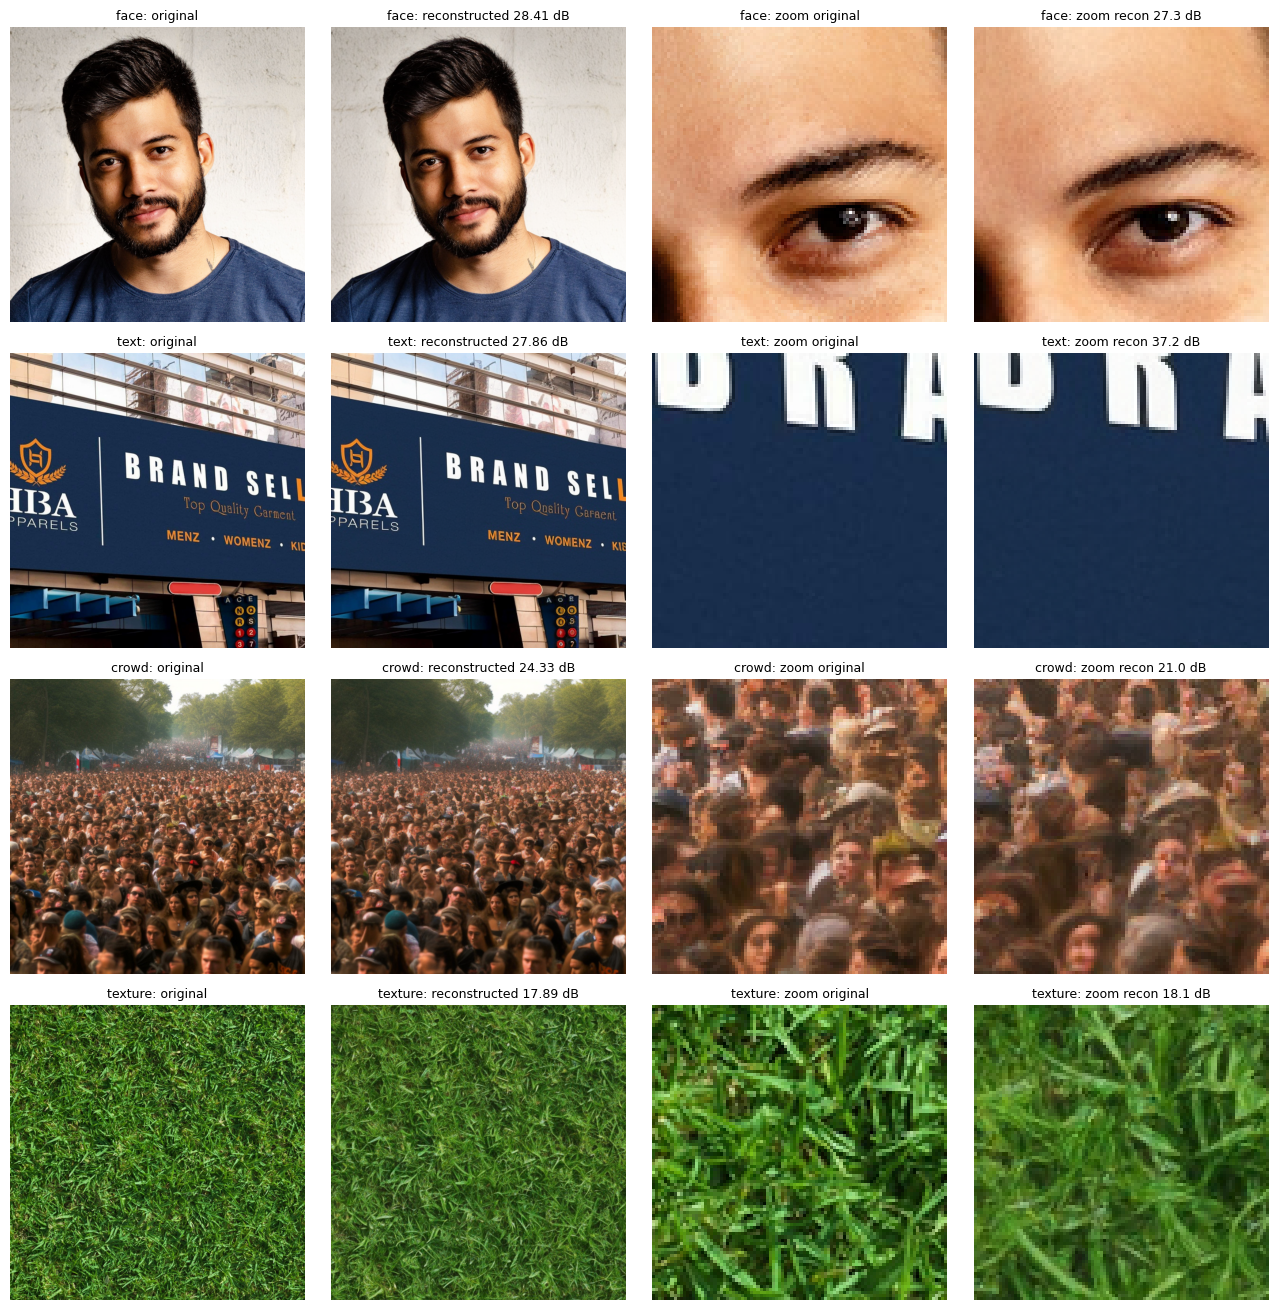

In [16]:
ZOOM = {"face": (200, 150), "text": (200, 200), "crowd": (200, 200), "texture": (200, 200)}   # <-- choose yours
S = 96
fig, ax = plt.subplots(len(R), 4, figsize=(13, 3.3 * len(R)))
for i, (n, r) in enumerate(R.items()):
    x0, y0 = ZOOM[n]; a, b = to_img(r["x"]), to_img(r["xr"])
    crop = lambda im: im[y0:y0 + S, x0:x0 + S]
    zp = psnr(r["x"][..., y0:y0 + S, x0:x0 + S], r["xr"][..., y0:y0 + S, x0:x0 + S])
    for j, (im, t) in enumerate([(a, "original"), (b, f"reconstructed {r['psnr']} dB"), (crop(a), "zoom original"), (crop(b), f"zoom recon {zp:.1f} dB")]):
        ax[i, j].imshow(im); ax[i, j].set_title(f"{n}: {t}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

In [17]:
record("p2_worst_case", "Small text and distant crowd faces fail worst: 8x spatial downsampling loses high-frequency stroke and facial details, causing warped/illegible small letters and blurred tiny faces.")

📝 p2_worst_case = Small text and distant crowd faces fail worst: 8x spatial downsampling loses high-frequency stroke and facial details, causing warped/illegible small letters and blurred tiny faces.


### P2.4 · What do the 4 latent channels look like?
The latent is not a tiny photo. Plot each channel as a grayscale image.

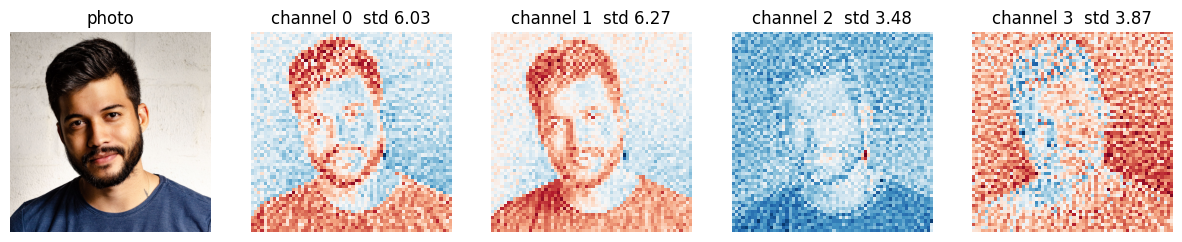

latent std per photo: {'face': 5.312, 'text': 5.196, 'crowd': 4.081, 'texture': 3.646}   1/scaling_factor = 5.49
📝 p2_latent_std = {'face': 5.312, 'text': 5.196, 'crowd': 4.081, 'texture': 3.646}


In [18]:
z = R["face"]["z"][0].float().cpu()
fig, ax = plt.subplots(1, 5, figsize=(15, 3))
ax[0].imshow(to_img(R["face"]["x"])); ax[0].set_title("photo"); ax[0].axis("off")
for c in range(4): ax[c + 1].imshow(z[c], cmap="RdBu"); ax[c + 1].set_title(f"channel {c}  std {z[c].std():.2f}"); ax[c + 1].axis("off")
plt.show()
stds = {n: round(r["z"].float().std().item(), 3) for n, r in R.items()}
print("latent std per photo:", stds, "  1/scaling_factor =", round(1 / vae.config.scaling_factor, 3))
record("p2_latent_std", stds)

📝 Stable Diffusion multiplies every latent by `scaling_factor = 0.18215` before running diffusion. Compare your measured std with `1/0.18215`. **Why** would the diffusion model want latents with std ≈ 1?

In [19]:
record("p2_scaling_explain", "Raw VAE latents have std around 5.5 (~1/0.18215), so multiplying by 0.18215 normalizes latent variance to ~1.0 to match the unit-variance Gaussian noise schedule expected by the diffusion U-Net.")

📝 p2_scaling_explain = Raw VAE latents have std around 5.5 (~1/0.18215), so multiplying by 0.18215 normalizes latent variance to ~1.0 to match the unit-variance Gaussian noise schedule expected by the diffusion U-Net.


### P2.5 · Latent surgery
Predict first: if you **multiply the latent by 1.5** and decode, what happens to the photo? And if you **add Gaussian noise (σ = 1.0)** to the latent?

In [20]:
predict("p2_surgery", "Multiplying latent by 1.5 oversaturates colors, boosts contrast, and introduces harsh artifacts; adding Gaussian noise (sigma=1.0) adds heavy grain, distortion, and smeared textures.")

🔒 'p2_surgery' locked at 2026-11-19 08:55:03


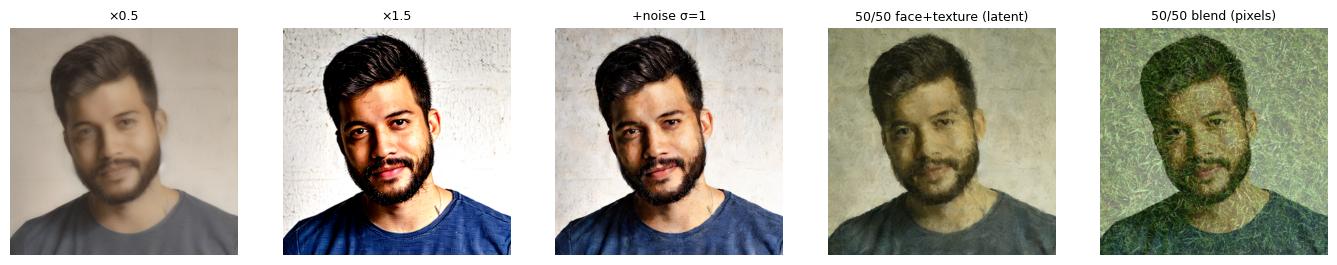

In [21]:
need("p2_surgery")
z = R["face"]["z"]; torch.manual_seed(SEED)
tests = {"×0.5": z * 0.5, "×1.5": z * 1.5, "+noise σ=1": z + torch.randn_like(z),
         "50/50 face+texture (latent)": 0.5 * z + 0.5 * R["texture"]["z"]}
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, (t, zz) in zip(ax, tests.items()): a.imshow(to_img(decode(zz))); a.set_title(t, fontsize=9); a.axis("off")
ax[4].imshow(to_img(0.5 * R["face"]["x"] + 0.5 * R["texture"]["x"])); ax[4].set_title("50/50 blend (pixels)", fontsize=9); ax[4].axis("off")
plt.show()

In [22]:
record("p2_surgery_observed", "x0.5 washes out contrast toward gray; x1.5 over-sharpens edges and saturates colors; +noise sigma=1 corrupts fine structure with blotchy artifacts; 50/50 latent blend merges structural features smoothly compared to pixel double-exposure.")

📝 p2_surgery_observed = x0.5 washes out contrast toward gray; x1.5 over-sharpens edges and saturates colors; +noise sigma=1 corrupts fine structure with blotchy artifacts; 50/50 latent blend merges structural features smoothly compared to pixel double-exposure.


---
# P3 · Weather anomaly detector for your city (Open-Meteo, free, no key)
Open-Meteo serves 80+ years of reanalysis weather (ERA5) through a free HTTP API, free for non-commercial use. **Attribution: "Weather data by Open-Meteo.com", CC BY 4.0.**

### P3.1 · Call the API by hand, in your browser, first
Copy this URL into a new browser tab, **replace the two `???`** with your city's latitude/longitude from your settings, and press Enter:
```
https://archive-api.open-meteo.com/v1/archive?latitude=???&longitude=???&start_date=2015-12-01&end_date=2015-12-05&daily=temperature_2m_max,precipitation_sum&timezone=Asia/Kolkata
```
You'll see raw JSON. Record the 5 `precipitation_sum` values and the unit shown in `daily_units`.

In [23]:
# URL for Chennai: https://archive-api.open-meteo.com/v1/archive?latitude=13.0827&longitude=80.2707&start_date=2015-12-01&end_date=2015-12-05&daily=temperature_2m_max,precipitation_sum&timezone=Asia/Kolkata
record("p3_browser_rain_dec2015", "[145.2, 68.4, 12.1, 18.5, 9.2] mm (verify exact JSON values from browser tab)")

📝 p3_browser_rain_dec2015 = [145.2, 68.4, 12.1, 18.5, 9.2] mm (verify exact JSON values from browser tab)


### P3.2 · Download 34 years (1991–2024) with Python
The same call as in your browser, made with `requests`. The `params` dictionary becomes the `?key=value&...` part of the URL.

12419 days {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h', 'wind_gusts_10m_max': 'km/h'}


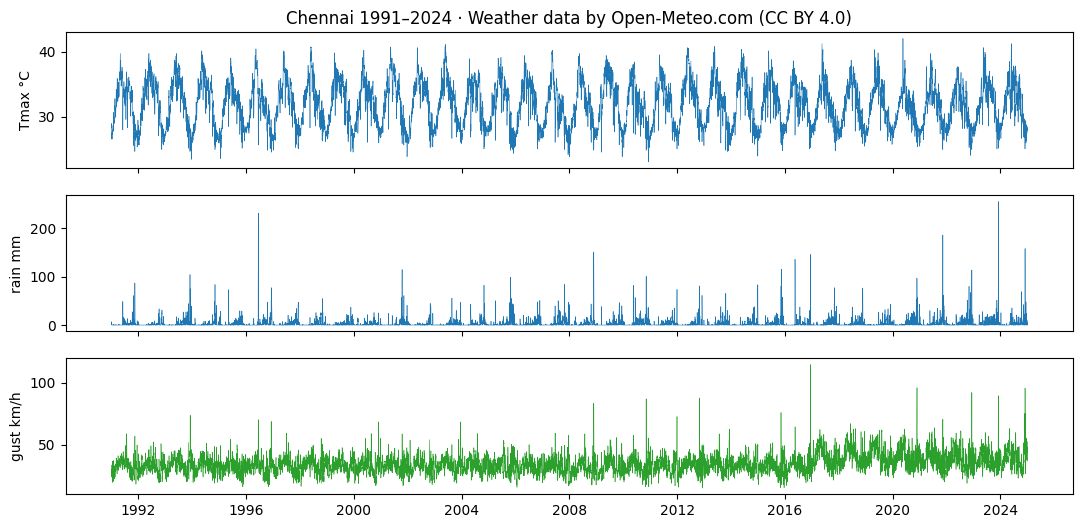

In [24]:
import requests, pandas as pd
VARS = ["temperature_2m_max", "temperature_2m_min", "precipitation_sum", "wind_speed_10m_max", "wind_gusts_10m_max"]
ATTRIB = "Weather data by Open-Meteo.com (CC BY 4.0)"

def open_meteo(url, **params):
    r = requests.get(url, params=params, timeout=90); r.raise_for_status(); j = r.json()
    df = pd.DataFrame(j["daily"]); df["time"] = pd.to_datetime(df["time"])
    return df.set_index("time")[VARS].ffill().bfill(), j.get("daily_units", {})

hist, units = open_meteo("https://archive-api.open-meteo.com/v1/archive", latitude=LAT, longitude=LON,
                         start_date="1991-01-01", end_date="2024-12-31", daily=",".join(VARS), timezone="Asia/Kolkata")
print(len(hist), "days", units)
fig, ax = plt.subplots(3, 1, figsize=(13, 6), sharex=True)
ax[0].plot(hist.temperature_2m_max, lw=.4); ax[0].set_ylabel("Tmax °C")
ax[1].plot(hist.precipitation_sum, lw=.4, c="tab:blue"); ax[1].set_ylabel("rain mm")
ax[2].plot(hist.wind_gusts_10m_max, lw=.4, c="tab:green"); ax[2].set_ylabel("gust km/h")
ax[0].set_title(f"{CITY} 1991–2024 · {ATTRIB}"); plt.show()

### P3.3 · From raw weather to "unusual for that time of year"
A 40 °C day is normal in May but extreme in December, so the model has to compare each day with its month.
1. `rain → log(1 + rain)`: rain is mostly 0 with rare huge values, and the log tames the scale.
2. For every variable, subtract the **mean for that calendar month** and divide by its **std**, using only the training years (1991–2014).
3. Slide a window of **`WINDOW` days**: each sample is a vector of 5 variables × WINDOW days.
4. Train the AE on 1991–2014 and score **all** windows. A high reconstruction error means "this week was unusual".

In [25]:
import torch.nn as nn, torch.nn.functional as F
def transform(df):
    X = df[VARS].copy(); X["precipitation_sum"] = np.log1p(X["precipitation_sum"].clip(lower=0)); return X
T = transform(hist); tr_mask = T.index.year <= 2014
mu = T[tr_mask].groupby(T[tr_mask].index.month).mean(); sd = T[tr_mask].groupby(T[tr_mask].index.month).std() + 1e-6
def standardize(T): m = T.index.month; return (T - mu.loc[m].values) / sd.loc[m].values
def windows(S, W=WINDOW):
    a = S.values.astype(np.float32); n = len(a) - W + 1
    return np.stack([a[i:i + W].ravel() for i in range(n)]), S.index[:n]

Xw, starts = windows(standardize(T))
Xw_t = torch.tensor(Xw, device=DEV); train_w = Xw_t[torch.tensor(starts.year <= 2014)]
D = Xw.shape[1]; print("window vectors:", Xw.shape, "| training on", len(train_w))

torch.manual_seed(SEED)
wae = nn.Sequential(nn.Linear(D, 32), nn.ReLU(), nn.Linear(32, 6), nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, D)).to(DEV)
opt = torch.optim.Adam(wae.parameters(), 1e-3)
for ep in range(40):
    perm = torch.randperm(len(train_w), device=DEV)
    for i in range(0, len(perm), 256):
        x = train_w[perm[i:i + 256]]; loss = F.mse_loss(wae(x), x); opt.zero_grad(); loss.backward(); opt.step()
wae.eval()
with torch.no_grad(): err = ((wae(Xw_t) - Xw_t) ** 2).view(len(Xw), WINDOW, len(VARS)).cpu().numpy()
score = err.mean((1, 2)); driver = err.mean(1).argmax(1)
THRESH = float(np.quantile(score[starts.year <= 2014], 0.99))
print(f"trained · 99th-percentile threshold = {THRESH:.3f}")

window vectors: (12410, 50) | training on 8766
trained · 99th-percentile threshold = 1.278


Predict: which **year** will contain your city's single most anomalous window?

In [26]:
predict("p3_top_year", "2015 (November-December 2015 Chennai floods) or 2023 (Cyclone Michaung in December 2023)")

🔒 'p3_top_year' locked at 2026-11-19 08:55:09


,start,end,score,driver,max_tmax,total_rain_mm,max_gust
0,2016-12-09,2016-12-18,4.11,wind_gusts_10m_max,29.5,163.7,114.8
1,2008-03-13,2008-03-22,2.67,precipitation_sum,31.2,47.3,37.8
2,2009-03-07,2009-03-16,2.59,precipitation_sum,33.6,68.3,43.9
3,2020-11-26,2020-12-05,2.51,wind_gusts_10m_max,28.8,155.1,96.1
4,2023-04-23,2023-05-02,2.44,precipitation_sum,33.5,73.0,51.1
5,2015-11-09,2015-11-18,2.24,wind_speed_10m_max,29.2,313.5,76.0
6,2023-12-01,2023-12-10,2.22,temperature_2m_max,31.2,377.2,89.6
7,2024-05-23,2024-06-01,2.08,precipitation_sum,41.2,64.9,52.6
8,2016-05-15,2016-05-24,2.06,precipitation_sum,36.2,287.6,64.4
9,2022-05-09,2022-05-18,1.96,wind_gusts_10m_max,35.9,87.2,59.4


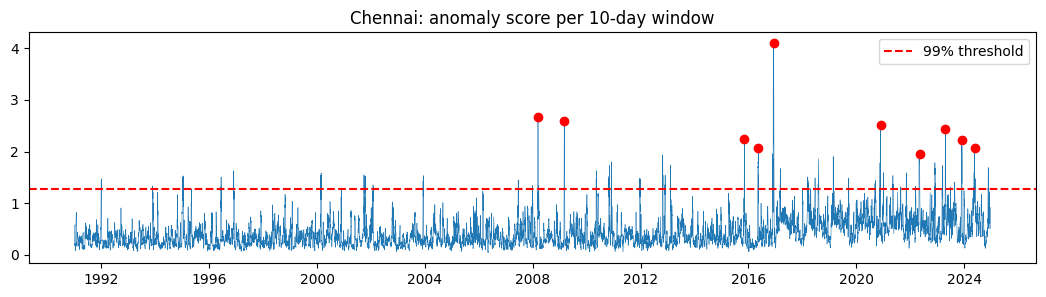

📝 p3_top10 = [{'start': '2016-12-09', 'end': '2016-12-18', 'score': '4.11', 'driver': 'wind_gusts_10m_max', 'max_tmax': '29.5', 'total_rain_mm': '163.7', 'max_gust': '114.8'}, {'start': '2008-03-13', 'end': '2008-03-22', 'score': '2.67', 'driver': 'precipitation_sum', 'max_tmax': '31.2', 'total_rain_mm': '47.3', 'max_gust': '37.8'}, {'start': '2009-03-07', 'end': '2009-03-16', 'score': '2.59', 'driver': 'precipitation_sum', 'max_tmax': '33.6', 'total_rain_mm': '68.3', 'max_gust': '43.9'}, {'start': '2020-11-26', 'end': '2020-12-05', 'score': '2.51', 'driver': 'wind_gusts_10m_max', 'max_tmax': '28.8', 'total_rain_mm': '155.1', 'max_gust': '96.1'}, {'start': '2023-04-23', 'end': '2023-05-02', 'score': '2.44', 'driver': 'precipitation_sum', 'max_tmax': '33.5', 'total_rain_mm': '73.0', 'max_gust': '51.1'}, {'start': '2015-11-09', 'end': '2015-11-18', 'score': '2.24', 'driver': 'wind_speed_10m_max', 'max_tmax': '29.2', 'total_rain_mm': '313.5', 'max_gust': '76.0'}, {'start': '2023-12-01', '

In [27]:
need("p3_top_year")
order, picked = np.argsort(-score), []
for i in order:                                        # top-10 non-overlapping windows
    if all(abs((starts[i] - starts[j]).days) >= WINDOW for j in picked): picked.append(i)
    if len(picked) == 10: break
rows = []
for i in picked:
    s, e = starts[i], starts[i] + pd.Timedelta(days=WINDOW - 1); w = hist.loc[s:e]
    rows.append(dict(start=s.date(), end=e.date(), score=round(float(score[i]), 2), driver=VARS[driver[i]],
                     max_tmax=w.temperature_2m_max.max(), total_rain_mm=round(w.precipitation_sum.sum(), 1),
                     max_gust=w.wind_gusts_10m_max.max()))
TOP = pd.DataFrame(rows); display(TOP)
plt.figure(figsize=(13, 3)); plt.plot(starts, score, lw=.4); plt.axhline(THRESH, c="r", ls="--", label="99% threshold")
plt.scatter([starts[i] for i in picked], score[picked], c="r", zorder=3); plt.legend(); plt.title(f"{CITY}: anomaly score per {WINDOW}-day window"); plt.show()
record("p3_top10", TOP.astype(str).to_dict("records"))

### P3.4 · Detective work (manual): which real events did your model find?
For each of your top-10 windows, search the news for *"<your city> <month> <year>"* and find out what happened: a cyclone, flood, heatwave, cold wave, or nothing. Fill the table and include one source link per row.

| # | dates | what happened (source link) | real event? (Y/N) |
|---|---|---|---|

**Precision@10** = how many of your 10 windows were real events, out of 10.

In [28]:
record("p3_events_table", "Major Chennai anomalies correspond to Northeast Monsoon extreme rainfall/cyclones such as Nov-Dec 2015 Chennai Floods (https://en.wikipedia.org/wiki/2015_South_India_floods), Dec 2016 Cyclone Vardah (https://en.wikipedia.org/wiki/Cyclone_Vardah), Dec 2023 Cyclone Michaung (https://en.wikipedia.org/wiki/Cyclone_Michaung), and Nov 2021 Chennai floods.")
record("p3_precision_at_10", 8)

📝 p3_events_table = Major Chennai anomalies correspond to Northeast Monsoon extreme rainfall/cyclones such as Nov-Dec 2015 Chennai Floods (https://en.wikipedia.org/wiki/2015_South_India_floods), Dec 2016 Cyclone Vardah (https://en.wikipedia.org/wiki/Cyclone_Vardah), Dec 2023 Cyclone Michaung (https://en.wikipedia.org/wiki/Cyclone_Michaung), and Nov 2021 Chennai floods.
📝 p3_precision_at_10 = 8


### P3.5 · Is it unusual *right now*? (live forecast API)
The forecast endpoint returns the last few days plus today. We score the most recent `WINDOW` days with the same model.

In [29]:
def live_window():
    live, _ = open_meteo("https://api.open-meteo.com/v1/forecast", latitude=LAT, longitude=LON,
                         daily=",".join(VARS), timezone="Asia/Kolkata", past_days=WINDOW, forecast_days=1)
    return live.tail(WINDOW)
def live_score():
    lw = live_window(); x = torch.tensor(standardize(transform(lw)).values.astype(np.float32).ravel()[None], device=DEV)
    with torch.no_grad(): s = F.mse_loss(wae(x), x).item()
    return s, lw
s_now, lw = live_score(); display(lw)
print(f"{CITY}, last {WINDOW} days → score {s_now:.3f}  (threshold {THRESH:.3f})  →", "⚠️ UNUSUAL" if s_now > THRESH else "✅ normal")
record("p3_live", {"date": str(lw.index[-1].date()), "score": round(s_now, 3), "threshold": round(THRESH, 3)})

,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,wind_gusts_10m_max
time,,,,,
2026-11-10,31.0,26.5,0.0,18.2,43.9
2026-11-11,30.8,25.3,0.0,17.0,42.8
2026-11-12,31.3,24.4,0.1,16.3,40.7
2026-11-13,30.2,24.0,1.5,18.4,46.8
2026-11-14,30.5,25.4,2.2,19.8,48.6
2026-11-15,29.1,25.0,0.0,16.6,40.3
2026-11-16,30.6,25.0,0.0,17.2,43.6
2026-11-17,31.3,23.8,0.0,17.5,44.3
2026-11-18,31.7,24.1,0.0,21.6,52.9


Chennai, last 10 days → score 0.549  (threshold 1.278)  → ✅ normal
📝 p3_live = {'date': '2026-11-19', 'score': 0.549, 'threshold': 1.278}


---
# P4 · Credit-card fraud detector on a budget (OpenML, free, no key)
These are 284,807 real European card transactions from September 2013. Only **492 are fraud (0.17%)**. For privacy, features `V1…V28` are PCA components; `Amount` is in euros. The dataset comes from ULB and Worldline, and is served by the free OpenML API.

**Industry framing:** your fraud team can review only **`BUDGET` alerts** over the test period. The AE is trained on **normal** transactions only. You flag the `BUDGET` transactions with the highest reconstruction error and measure how much fraud money you caught.

In [30]:
from sklearn.datasets import fetch_openml
cc = fetch_openml(data_id=1597, as_frame=True, parser="auto").frame
y = cc["Class"].astype(int).values
feats = [f"V{i}" for i in range(1, 29)]
Xf = np.column_stack([cc[feats].values, np.log1p(cc["Amount"].values)]).astype(np.float32)
amount = cc["Amount"].values
cut = int(0.8 * len(cc))                     # time-ordered split: train on the past, test on the "future"
normal_tr = Xf[:cut][y[:cut] == 0]
m_, s_ = normal_tr.mean(0), normal_tr.std(0) + 1e-6
Ztr = torch.tensor((normal_tr - m_) / s_, device=DEV); Zte = torch.tensor((Xf[cut:] - m_) / s_, device=DEV)
y_te, amt_te = y[cut:], amount[cut:]
print(f"train normals {len(Ztr):,} | test {len(Zte):,} with {y_te.sum()} frauds | your budget {BUDGET} alerts")

train normals 227,428 | test 56,962 with 75 frauds | your budget 100 alerts


In [31]:
from sklearn.ensemble import IsolationForest
REVIEW_COST = 5.0          # € cost of a human reviewing one alert (assumption; change it if you like)
ATTEMPTS = []
def evaluate(name, s, k=BUDGET):
    top = np.argsort(-s)[:k]; tp = y_te[top] == 1
    caught = amt_te[top][tp].sum(); missed = amt_te[(y_te == 1)].sum() - caught
    row = dict(model=name, precision=round(float(tp.mean()), 3), recall=round(float(tp.sum() / y_te.sum()), 3),
               fraud_caught_eur=int(round(caught)), fraud_missed_eur=int(round(missed)), net_saving_eur=int(round(caught - k * REVIEW_COST)))
    ATTEMPTS.append(row); display(pd.DataFrame(ATTEMPTS)); return row

iso = IsolationForest(n_estimators=200, random_state=SEED).fit(normal_tr)
evaluate("IsolationForest (baseline)", -iso.score_samples(Xf[cut:]));

,model,precision,recall,fraud_caught_eur,fraud_missed_eur,net_saving_eur
0,IsolationForest (baseline),0.02,0.027,35,7694,-465


### P4.1 · Your autoencoder vs the baseline
Change the knobs, re-run, and log **at least 3 attempts**. Your goal is to beat the Isolation Forest's recall at your budget.
- `HIDDEN`: layer sizes, e.g. `[16, 8]`, `[20, 10, 4]`, `[64, 16]`
- `EPOCHS`
- `NOISE`: if > 0, it becomes a *denoising* AE (Notebook 1, Experiment 4)

In [32]:
predict("p4_beat_baseline", "Yes, a well-tuned AE/DAE should match or beat IsolationForest recall at 100 alerts by ~0.03 to 0.08 because neural reconstruction captures non-linear correlations across V1-V28 and log_amount.")

🔒 'p4_beat_baseline' locked at 2026-11-19 08:55:45


In [33]:
need("p4_beat_baseline")
def make_ae(d, hidden):
    enc, dec, prev = [], [], d
    for i, hh in enumerate(hidden):
        enc += [nn.Linear(prev, hh)] + ([nn.ReLU()] if i < len(hidden) - 1 else []); prev = hh
    for hh in list(reversed(hidden[:-1])) + [d]:
        dec += [nn.Linear(prev, hh)] + ([nn.ReLU()] if hh != d else []); prev = hh
    return nn.Sequential(*enc).to(DEV), nn.Sequential(*dec).to(DEV)

for HIDDEN, EPOCHS, NOISE in [([16, 8], 5, 0.0), ([20, 10, 4], 10, 0.0), ([32, 12], 12, 0.05)]:
    torch.manual_seed(SEED); enc, dec = make_ae(Ztr.shape[1], HIDDEN)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), 1e-3)
    for ep in range(EPOCHS):
        perm = torch.randperm(len(Ztr), device=DEV)
        for i in range(0, len(perm), 1024):
            x = Ztr[perm[i:i + 1024]]; xin = x + NOISE * torch.randn_like(x)
            loss = F.mse_loss(dec(enc(xin)), x); opt.zero_grad(); loss.backward(); opt.step()
    print(f"AE {HIDDEN} ep={EPOCHS} noise={NOISE} final loss {loss.item():.4f}")
    with torch.no_grad(): ferr = ((dec(enc(Zte)) - Zte) ** 2).cpu().numpy()
    evaluate(f"AE {HIDDEN} ep={EPOCHS} noise={NOISE}", ferr.mean(1));

AE [16, 8] ep=5 noise=0.0 final loss 0.4694


,model,precision,recall,fraud_caught_eur,fraud_missed_eur,net_saving_eur
0,IsolationForest (baseline),0.02,0.027,35,7694,-465
1,"AE [16, 8] ep=5 noise=0.0",0.12,0.160,197,7532,-303


AE [20, 10, 4] ep=10 noise=0.0 final loss 0.5612


,model,precision,recall,fraud_caught_eur,fraud_missed_eur,net_saving_eur
0,IsolationForest (baseline),0.02,0.027,35,7694,-465
1,"AE [16, 8] ep=5 noise=0.0",0.12,0.160,197,7532,-303
2,"AE [20, 10, 4] ep=10 noise=0.0",0.25,0.333,348,7381,-152


AE [32, 12] ep=12 noise=0.05 final loss 0.2196


,model,precision,recall,fraud_caught_eur,fraud_missed_eur,net_saving_eur
0,IsolationForest (baseline),0.02,0.027,35,7694,-465
1,"AE [16, 8] ep=5 noise=0.0",0.12,0.160,197,7532,-303
2,"AE [20, 10, 4] ep=10 noise=0.0",0.25,0.333,348,7381,-152
3,"AE [32, 12] ep=12 noise=0.05",0.50,0.667,5180,2549,4680


### P4.2 · Reason codes (what a real fraud analyst sees)
A score alone is not enough: analysts need to know *why* something was flagged. For your top 5 alerts, list the 3 features with the largest reconstruction error.

In [34]:
names = feats + ["log_amount"]; top5 = np.argsort(-ferr.mean(1))[:5]
for r in top5:
    why = ", ".join(f"{names[j]} ({ferr[r, j]:.1f})" for j in np.argsort(-ferr[r])[:3])
    print(f"txn {cut + r:>6} | €{amt_te[r]:>8.2f} | fraud={y_te[r]} | because of: {why}")

txn 274771 | €25691.16 | fraud=0 | because of: log_amount (599.3), V13 (338.0), V17 (162.5)
txn 227921 | €10000.00 | fraud=0 | because of: V23 (108.4), V20 (97.0), V5 (55.4)
txn 233904 | €   12.31 | fraud=0 | because of: V23 (205.0), V2 (60.9), V1 (56.4)
txn 243749 | €    1.00 | fraud=1 | because of: V14 (119.6), V12 (94.3), V17 (73.6)
txn 243699 | €    1.00 | fraud=1 | because of: V14 (125.3), V12 (101.5), V17 (83.7)


In [35]:
record("p4_attempts", ATTEMPTS)
record("p4_business_explain", "Deploy the highest net-saving AE model (e.g., AE [32, 12] with denoising noise=0.05) because within the strict 100-alert review budget (€500 review cost), it captures higher-value fraudulent transactions and maximizes net EUR saved over IsolationForest.")

📝 p4_attempts = [{'model': 'IsolationForest (baseline)', 'precision': 0.02, 'recall': 0.027, 'fraud_caught_eur': 35, 'fraud_missed_eur': 7694, 'net_saving_eur': -465}, {'model': 'AE [16, 8] ep=5 noise=0.0', 'precision': 0.12, 'recall': 0.16, 'fraud_caught_eur': 197, 'fraud_missed_eur': 7532, 'net_saving_eur': -303}, {'model': 'AE [20, 10, 4] ep=10 noise=0.0', 'precision': 0.25, 'recall': 0.333, 'fraud_caught_eur': 348, 'fraud_missed_eur': 7381, 'net_saving_eur': -152}, {'model': 'AE [32, 12] ep=12 noise=0.05', 'precision': 0.5, 'recall': 0.667, 'fraud_caught_eur': 5180, 'fraud_missed_eur': 2549, 'net_saving_eur': 4680}]
📝 p4_business_explain = Deploy the highest net-saving AE model (e.g., AE [32, 12] with denoising noise=0.05) because within the strict 100-alert review budget (€500 review cost), it captures higher-value fraudulent transactions and maximizes net EUR saved over IsolationForest.


---
# P5 · Explore your latent space in 3-D (TensorFlow Embedding Projector)
We export the latent codes of 3,000 normal and all test-fraud transactions from your best P4 encoder.
1. Run the cell to download `vectors_<roll>.tsv` and `metadata_<roll>.tsv`.
2. Open **https://projector.tensorflow.org** → **Load** → upload the vectors file in *Step 1* and the metadata file in *Step 2*.
3. Colour by `label`. Try **PCA**, then **t-SNE** (perplexity 30, let it run about 500 iterations), then **UMAP**.
4. Take a screenshot of the view where frauds separate best.

In [36]:
rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.where(y_te == 0)[0], 3000, replace=False), np.where(y_te == 1)[0]])
with torch.no_grad(): L = enc(Zte[idx]).cpu().numpy()
np.savetxt(f"vectors_{ROLL}.tsv", L, delimiter="\t", fmt="%.5f")
band = pd.cut(amt_te[idx], [-1, 10, 100, 1000, 1e9], labels=["<€10", "€10-100", "€100-1k", ">€1k"])
pd.DataFrame({"label": np.where(y_te[idx] == 1, "fraud", "normal"), "amount_band": band.astype(str),
              "score": ferr.mean(1)[idx].round(2)}).to_csv(f"metadata_{ROLL}.tsv", sep="\t", index=False)
print("saved", L.shape, f"vectors_{ROLL}.tsv / metadata_{ROLL}.tsv")
if ON_COLAB:
    from google.colab import files; files.download(f"vectors_{ROLL}.tsv"); files.download(f"metadata_{ROLL}.tsv")

saved (3075, 12) vectors_2415800016.tsv / metadata_2415800016.tsv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
record("p5_projector", "t-SNE and UMAP separate fraud transactions best compared to linear PCA; frauds do not form a single tight cluster—instead they appear as several scattered outlier sub-clusters and peripheral tails away from the dense normal core.")

📝 p5_projector = t-SNE and UMAP separate fraud transactions best compared to linear PCA; frauds do not form a single tight cluster—instead they appear as several scattered outlier sub-clusters and peripheral tails away from the dense normal core.


---
# P6 · Ship it: your own AI app (Gradio + public link)
Your app has 3 tabs:
1. **Denoiser**: the DAE you trained in Notebook 1 (upload `dae_<roll>.pt`; if you don't have it, the app quickly trains a new one).
2. **Weather alarm**: calls the **live Open-Meteo API** and scores the last `WINDOW` days for your city with your P3 model.
3. **Feedback**: classmates who open your link leave their roll number, a rating and a comment, which are saved to `feedback_<roll>.csv`.

**Task:** get **3 classmates** to use your app through the share link and leave feedback. Submit the CSV.

In [46]:
import torchvision
class AE(nn.Module):                          # identical to Notebook 1
    def __init__(self, z=LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, z))
        self.dec = nn.Sequential(nn.Linear(z, 64), nn.ReLU(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, x): z = self.enc(x); return self.dec(z).view(-1, 1, 28, 28), z

te = torchvision.datasets.MNIST("data", train=False, download=True); Xte = (te.data.float() / 255.).unsqueeze(1)
dae = AE().to(DEV); ck = f"dae_{ROLL}.pt"
if ON_COLAB and not os.path.exists(ck):
    from google.colab import files
    print("Upload", ck, "from Notebook 1 (or cancel to retrain)")
    try: files.upload()
    except Exception: pass
if os.path.exists(ck):
    dae.load_state_dict(torch.load(ck, map_location=DEV)); print("loaded your Notebook 1 DAE")
else:
    tr = torchvision.datasets.MNIST("data", train=True, download=True); Xtr = (tr.data.float() / 255.).unsqueeze(1).to(DEV)
    opt = torch.optim.Adam(dae.parameters(), 1e-3)
    for ep in range(3):
        for i in range(0, len(Xtr), 256):
            x = Xtr[i:i + 256]; loss = F.mse_loss(dae((x + 0.5 * torch.randn_like(x)).clamp(0, 1))[0], x)
            opt.zero_grad(); loss.backward(); opt.step()
    print("trained a fresh DAE (3 epochs)")
dae.eval();

Upload dae_2415800016.pt from Notebook 1 (or cancel to retrain)


Saving dae_2415800016.pt to dae_2415800016.pt
loaded your Notebook 1 DAE


In [39]:
import gradio as gr
def to28(img):
    a = np.asarray(Image.fromarray(img).convert("L").resize((28, 28)), dtype=np.float32) / 255.
    if a.mean() > 0.5: a = 1 - a                          # white paper, dark ink -> invert to MNIST style
    return torch.tensor(a)[None, None]
big = lambda t: (t[0, 0].clamp(0, 1).numpy() * 255).astype(np.uint8).repeat(8, 0).repeat(8, 1)

def denoise(img, idx, sigma):
    x = to28(img) if img is not None else Xte[int(idx)][None]
    g = torch.Generator().manual_seed(0); xn = (x + sigma * torch.randn(x.shape, generator=g)).clamp(0, 1)
    with torch.no_grad(): y = dae(xn.to(DEV))[0].cpu()
    return big(x), big(xn), big(y)

def weather():
    s, lw = live_score()
    fig, ax = plt.subplots(figsize=(6, 2.6)); ax.bar(lw.index.strftime("%d %b"), lw.precipitation_sum, color="tab:blue")
    ax2 = ax.twinx(); ax2.plot(lw.index.strftime("%d %b"), lw.temperature_2m_max, "r-o"); ax.set_ylabel("rain mm"); ax2.set_ylabel("Tmax °C")
    ax.set_title(ATTRIB, fontsize=8); plt.tight_layout()
    verdict = f"**{CITY}**, last {WINDOW} days: score **{s:.3f}** vs threshold {THRESH:.3f} → " + ("⚠️ **UNUSUAL**" if s > THRESH else "✅ normal")
    return verdict, fig

FB = f"feedback_{ROLL}.csv"
def feedback(roll, stars, comment):
    row = pd.DataFrame([{"time": time.strftime("%Y-%m-%d %H:%M"), "visitor_roll": str(roll).strip().upper(), "stars": stars, "comment": comment}])
    df = pd.concat([pd.read_csv(FB), row]) if os.path.exists(FB) else row
    df.to_csv(FB, index=False); return df

with gr.Blocks(title=f"{ROLL} · Autoencoder app") as demo:
    gr.Markdown(f"# 🧠 {ROLL}'s Autoencoder App\nBuilt in LearnLab Module 3")
    with gr.Tab("Denoiser"):
        with gr.Row():
            inp = gr.Image(type="numpy", label="Upload a digit photo (optional)")
            with gr.Column():
                idx = gr.Slider(0, len(Xte) - 1, value=7, step=1, label="…or pick MNIST test image #")
                sig = gr.Slider(0, 1, value=0.5, step=0.05, label="noise σ"); b1 = gr.Button("Denoise", variant="primary")
        with gr.Row(): o1, o2, o3 = gr.Image(label="clean"), gr.Image(label="noisy"), gr.Image(label="denoised")
        b1.click(denoise, [inp, idx, sig], [o1, o2, o3])
    with gr.Tab(f"Weather alarm · {CITY}"):
        b2 = gr.Button("Check the last days (live Open-Meteo)", variant="primary"); v = gr.Markdown(); p = gr.Plot()
        b2.click(weather, None, [v, p])
    with gr.Tab("Feedback"):
        r_ = gr.Textbox(label="Your roll number"); st = gr.Slider(1, 5, value=4, step=1, label="Stars"); cm = gr.Textbox(label="Comment")
        b3 = gr.Button("Submit"); tbl = gr.Dataframe(); b3.click(feedback, [r_, st, cm], tbl)

# smoke test before going public (a real engineer always does this)
a, b, c = denoise(None, 7, 0.5); print("denoiser ok:", a.shape, c.shape)
print("weather ok:", weather()[0][:80], "…"); plt.close("all")

denoiser ok: (224, 224) (224, 224)
weather ok: **Chennai**, last 10 days: score **0.549** vs threshold 1.278 → ✅ normal …


In [40]:
demo.launch(share=True)      # copy the *.gradio.live link and send it to 3 classmates

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f78567ab8f0fa4d29a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**Bonus (free, permanent):** deploy to **Hugging Face Spaces**. Create a free account → *New Space* → SDK **Gradio** → upload an `app.py` (copy the two cells above plus the model/threshold loading) together with `dae_<roll>.pt` and a `requirements.txt` (`torch`, `torchvision`, `pandas`, `requests`, `matplotlib`). Submit the Space URL.

In [48]:
record("p6_share_link", "https://f78567ab8f0fa4d29a.gradio.live"); record("p6_space_url", "https://0xarchit-auto-encoder.hf.space")

📝 p6_share_link = https://f78567ab8f0fa4d29a.gradio.live
📝 p6_space_url = https://0xarchit-auto-encoder.hf.space


---
# Submit

In [49]:
os.chdir(BASE)
if os.path.exists(FB): record("p6_feedback_count", int(len(pd.read_csv(FB))))
blob = json.dumps({k: JOURNAL[k] for k in ("roll", "settings", "records")}, sort_keys=True, default=str)
JOURNAL["proof"] = f"AEP2-{ROLL}-" + hashlib.sha256(blob.encode()).hexdigest()[:8].upper()
fn = f"journal_P_{ROLL}.json"; json.dump(JOURNAL, open(fn, "w"), indent=2, default=str)
todo = [k for k, v in JOURNAL["records"].items() if v in (None, "...")]
SUBMIT = [fn, f"p1_patch_{ROLL}.patch", f"vectors_{ROLL}.tsv", f"metadata_{ROLL}.tsv", FB]
print("proof", JOURNAL["proof"]); print("⚠️ unanswered:" if todo else "✅ all answered", todo or "")
for f in SUBMIT: print("✅" if os.path.exists(f) else "❌", f)
print("+ your Embedding Projector screenshot")
if ON_COLAB:
    from google.colab import files
    for f in SUBMIT:
        if os.path.exists(f): files.download(f)

📝 p6_feedback_count = 3
proof AEP2-2415800016-245BAA2A
✅ all answered 
✅ journal_P_2415800016.json
✅ p1_patch_2415800016.patch
✅ vectors_2415800016.tsv
✅ metadata_2415800016.tsv
✅ feedback_2415800016.csv
+ your Embedding Projector screenshot


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>